# Assignment 1 – EDA & Baseline

**Group 57** – Berke Vural (23118080755)

Competition: [MITSUI&CO. Commodity Prediction Challenge](https://www.kaggle.com/competitions/mitsui-commodity-prediction-challenge)

## 1. Problem Definition

**Task.** We predict future returns of financial instruments related to commodities.
The data are daily prices from four markets: LME (metals), JPX (Japanese futures),
US stocks and Forex (exchange rates).

**Target.** `train_labels.csv` has 424 target columns (`target_0` ... `target_423`).
Each target is one of these:

- the log return of one instrument (4 targets),
- the log return of instrument A minus the log return of instrument B (420 targets).

The return is measured over `lag` days, where `lag` is 1, 2, 3 or 4.
For a single instrument the target on day `t` is:

`target(t) = log(price[t + lag + 1] / price[t + 1])`

`target_pairs.csv` shows the instrument(s) and the lag of each target.
This is a regression problem with 424 outputs.

**Metric.** For each day, the Spearman rank correlation between our 424 predictions
and the 424 true targets is computed. The final score is the mean of these daily
correlations divided by their standard deviation (a Sharpe-ratio-like score).
This means:

- only the order of the predictions within a day matters, not the exact values,
- a model that is a little bit right every day is better than a model that is
  very right on some days and wrong on others.

## 2. Data Overview

We load the data with the `load_data` function from `src/data.py`.

In [1]:
from src.data import load_data

train, labels, target_pairs = load_data()

print("train:       ", train.shape)
print("labels:      ", labels.shape)
print("target_pairs:", target_pairs.shape)

train:        (1961, 558)
labels:       (1961, 425)
target_pairs: (424, 3)


- `train` has 1961 days. It has 557 price/volume columns plus `date_id`.
- `labels` has the same 1961 days and 424 target columns plus `date_id`.
- `target_pairs` has one row for each target.

We have many more columns (557) than rows (1961). This is important for the model:
a model with too many inputs can easily overfit.

In [2]:
print(train.dtypes.value_counts())
print(labels.dtypes.value_counts())

float64    557
int64        1
Name: count, dtype: int64
float64    424
int64        1
Name: count, dtype: int64


All feature and target columns are numbers (`float64`). Only `date_id` is an integer.
There are no categorical columns, so we do not need any encoding.

In [3]:
markets = train.columns[1:].str.split("_").str[0]
markets.value_counts()

US     475
JPX     40
FX      38
LME      4
Name: count, dtype: int64

Most columns come from US stocks (475 of 557). JPX has 40 columns, Forex 38 and LME only 4.
So the data is not balanced between markets. The US stocks will have the biggest
effect on a model that uses all columns.

In [4]:
example_cols = ["LME_AH_Close", "JPX_Gold_Standard_Futures_Close",
                "US_Stock_VT_adj_close", "FX_USDJPY"]
train[example_cols].describe()

,LME_AH_Close,JPX_Gold_Standard_Futures_Close,US_Stock_VT_adj_close,FX_USDJPY
count,1910.000000,1845.000000,1894.000000,1961.000000
mean,2252.202853,7699.157182,86.056667,124.678585
std,398.544566,3067.132209,19.023997,18.301781
min,1462.000000,4174.000000,49.206300,102.678985
25%,1925.250000,5197.000000,66.942075,108.926003
50%,2245.500000,6621.000000,86.783800,113.564498
75%,2512.000000,8953.000000,97.722300,143.853034
max,3849.000000,16306.000000,132.681854,161.608501


The prices have very different scales. For example, JPX gold is around 7700,
LME aluminium around 2250 and the US stock VT around 86.
A model like linear regression is sensitive to scale, so we will scale the inputs.

The `count` row is smaller than 1961 for most columns (for example 1845 for JPX gold).
So there are missing values. We look at them in the next part.

In [5]:
labels[["target_0", "target_1", "target_106", "target_423"]].describe()

,target_0,target_1,target_106,target_423
count,1827.000000,1784.000000,1827.000000,1768.000000
mean,0.000470,-0.000575,0.000457,-0.003327
std,0.011925,0.016930,0.015297,0.053855
min,-0.123763,-0.120442,-0.164627,-0.212359
25%,-0.004567,-0.010452,-0.006850,-0.032805
50%,0.000928,-0.000954,0.001381,-0.002256
75%,0.006270,0.008901,0.008887,0.027942
max,0.087470,0.113968,0.115999,0.244952


The targets are small numbers with a mean close to 0. This is normal for daily returns.
The standard deviation is about 0.01–0.02 for lag 1, but 0.05 for `target_423` (lag 4),
because a return over 4 days changes more than a return over 1 day.
The min and max values (for example −0.12 and 0.09 for `target_0`) are far from the
quartiles, so the targets have some extreme values (outliers).

In [6]:
missing = train.drop(columns="date_id").isna().mean() * 100
missing.groupby(markets).mean().round(1)

FX     0.0
JPX    5.9
LME    2.6
US     4.3
dtype: float64

In [7]:
missing.sort_values(ascending=False).head(8)

US_Stock_GOLD_adj_open           87.353391
US_Stock_GOLD_adj_close          87.353391
US_Stock_GOLD_adj_volume         87.353391
US_Stock_GOLD_adj_low            87.353391
US_Stock_GOLD_adj_high           87.353391
JPX_Gold_Mini_Futures_Low         5.915349
JPX_Gold_Standard_Futures_Low     5.915349
JPX_Platinum_Mini_Futures_Low     5.915349
dtype: float64

Forex has no missing values. JPX (5.9 %), US (4.3 %) and LME (2.6 %) have a few.
They are missing on days when that exchange was closed (holidays and time zone
differences). For example, on 67 days all US columns are empty.

The five `US_Stock_GOLD_*` columns are 87 % empty: they only have values for the
first 259 days. They carry almost no information, so we will drop them.
The other missing values are few, so we will fill them in the preprocessing step.

In [8]:
target_missing = labels.drop(columns="date_id").isna().mean() * 100
print("Average missing % in targets:", round(target_missing.mean(), 1))
print("Max missing % in one target: ", round(target_missing.max(), 1))

Average missing % in targets: 10.5
Max missing % in one target:  18.9


The targets are missing 10.5 % of the time on average (up to 18.9 %). A target is
missing when one of its instruments did not trade. We must not fill the targets,
because that would mean inventing the answer. Missing targets are skipped when
we train and evaluate the model.

In [9]:
print("Duplicate rows:    ", train.duplicated().sum())
print("Duplicate date_ids:", train["date_id"].duplicated().sum())

Duplicate rows:     0
Duplicate date_ids: 0


There are no duplicate rows and every `date_id` appears only once.
So each row is one unique day and we do not need to remove anything.

## 3. Exploratory Data Analysis

### 3.1 Distribution of the targets

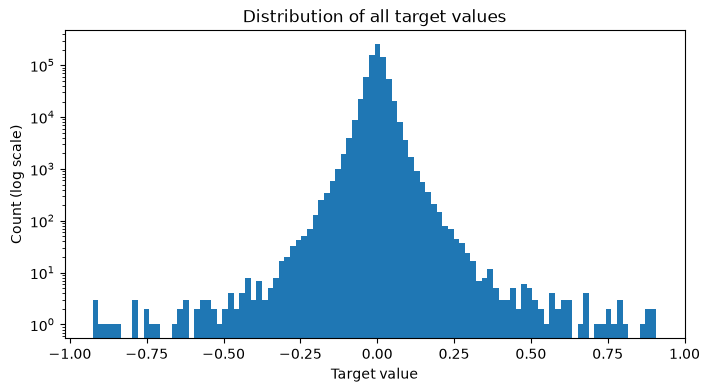

In [10]:
import matplotlib.pyplot as plt

all_targets = labels.drop(columns="date_id").stack()

plt.figure(figsize=(8, 4))
plt.hist(all_targets, bins=100)
plt.yscale("log")
plt.title("Distribution of all target values")
plt.xlabel("Target value")
plt.ylabel("Count (log scale)")
plt.show()

In [11]:
print("Skewness:", round(all_targets.skew(), 2))
print("Kurtosis:", round(all_targets.kurt(), 2))
print("Values between -0.05 and 0.05:", round((all_targets.abs() < 0.05).mean() * 100, 1), "%")

Skewness: 0.1
Kurtosis: 34.0
Values between -0.05 and 0.05: 82.0 %


The targets are centred around 0 and the distribution is almost symmetric (skewness 0.1).
82 % of the values are between −0.05 and 0.05. But the tails are very long: some values
reach ±0.9. The kurtosis is 34, much bigger than 0 for a normal distribution, so there
are many more extreme values than in a normal distribution.

What this means for us:
- The competition metric uses ranks (Spearman), so a few extreme values do not
  change the score much.
- A linear regression trained with squared error is sensitive to extreme values,
  so these outliers can pull the model. We keep this in mind for the baseline.

### 3.2 Spread of the targets by lag

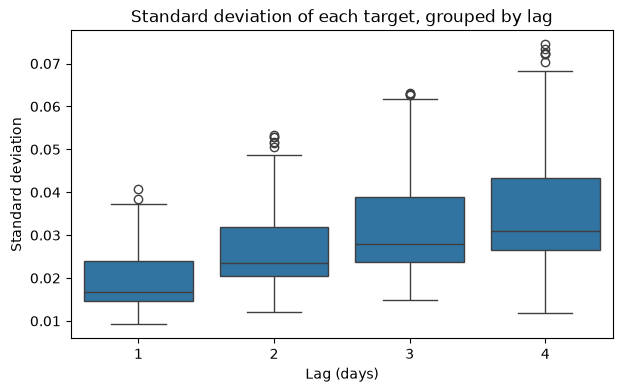

In [12]:
import seaborn as sns

std_by_lag = target_pairs.copy()
std_by_lag["std"] = labels.drop(columns="date_id").std().values

plt.figure(figsize=(7, 4))
sns.boxplot(data=std_by_lag, x="lag", y="std")
plt.title("Standard deviation of each target, grouped by lag")
plt.xlabel("Lag (days)")
plt.ylabel("Standard deviation")
plt.show()

The spread of the targets grows with the lag. The median standard deviation is about
0.017 for lag 1 and 0.031 for lag 4. This makes sense: a return over 4 days can move
more than a return over 1 day.

Inside each lag, some targets are much more volatile than others (the points above
the boxes). The most volatile targets are lag 4 pairs of an LME or JPX metal with a US mining
or energy stock, with a standard deviation around 0.07.

Because the metric compares the 424 predictions of one day by rank, the model should
not simply predict bigger values for lag 4 targets. It has to get the order right.